#### **Session 6 · Notebook 5 — Grad-CAM: Which areas (features) of the image are important?**

Session 6 deck, *Working with CNNs (II): transfer learning*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

Three models, the same test images:
1. the **Session 5** maximum network, trained from scratch (`nb4_max.keras` from Session 5, if you have it);
2. **ResNet50** fine-tuned (Notebook 2);
3. **EfficientNet** pushed to the limit (Notebook 4).

Grad-CAM (Selvaraju et al., 2017): weight each feature map of the last convolutional layer by the gradient of
the score, sum, keep the positive part.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(1337)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792091986.871391   81970 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792091988.406965   81970 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
IMG_SIZE = (224, 224)  # pretrained ImageNet models were trained at 224 x 224 (or larger)
BATCH = 64                 # same batch size as Session 5 => exactly the same test images
SEED = 1337                # same seed as Session 5 => same train / val / test split
WEIGHTS = "imagenet"       # pretrained weights (None = random weights, only for testing the code)
QUICK = False              # True: ~20% of the training batches (fast trial run)

In [3]:
# --- 1. Download the Kaggle Cats and Dogs data (Microsoft PetImages) -----------------------------
URL = ("https://download.microsoft.com/download/3/E/1/"
       "3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip")
DATA_DIR = "PetImages"
if not os.path.isdir(DATA_DIR):
    print("Downloading (about 790 MB)...")
    urllib.request.urlretrieve(URL, "catsdogs.zip")
    with zipfile.ZipFile("catsdogs.zip") as z:
        z.extractall(".")
    os.remove("catsdogs.zip")

# --- 2. Clean once, in two steps -----------------------------------------------------------------
# (a) EXACTLY the Session 5 rule: delete every file without a JFIF header. This keeps the same files
#     as Session 5, so the 70/15/15 split and the 3,503 test images are identical.
# (b) Re-encode the remaining files as standard RGB JPEGs (removes the "Corrupt JPEG data" warnings);
#     delete any file that still cannot be opened.
from PIL import Image
import shutil
MARK = os.path.join(DATA_DIR, ".cleaned_v2")
if os.path.exists(os.path.join(DATA_DIR, ".cleaned")) and not os.path.exists(MARK):
    # folder cleaned by an earlier version of this notebook: the JFIF rule can no longer be applied
    print("Old cleaning detected: downloading the data again...")
    shutil.rmtree(DATA_DIR)
    urllib.request.urlretrieve(URL, "catsdogs.zip")
    with zipfile.ZipFile("catsdogs.zip") as z:
        z.extractall(".")
    os.remove("catsdogs.zip")
if not os.path.exists(MARK):
    no_jfif, unreadable = [], []
    for folder in ("Cat", "Dog"):
        path = os.path.join(DATA_DIR, folder)
        for fname in os.listdir(path):
            fpath = os.path.join(path, fname)
            try:                                              # (a) Session 5 rule
                with open(fpath, "rb") as f:
                    ok = b"JFIF" in f.peek(10)
            except OSError:
                ok = False
            if not ok:
                os.remove(fpath); no_jfif.append(f"{folder}/{fname}"); continue
            try:                                              # (b) re-encode
                with Image.open(fpath) as im:
                    im = im.convert("RGB"); im.load()
                im.save(fpath, "JPEG", quality=95)
            except Exception:
                os.remove(fpath); unreadable.append(f"{folder}/{fname}")
    open(MARK, "w").write("\n".join(no_jfif + unreadable))
    print(len(no_jfif), "files without JFIF header removed (as in Session 5);",
          len(unreadable), "unreadable files removed")
for folder in ("Cat", "Dog"):
    print(folder, len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Cat 11741 images
Dog 11669 images


In [4]:
# --- 3. Train / validation / test: 70 / 15 / 15, identical to Session 5 --------------------------
# Session 5 had 3,503 test images; if the line below shows another number, the files differ.
train_ds, rest_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.3, subset="both", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")
class_names = train_ds.class_names
n_rest = int(rest_ds.cardinality())
val_ds, test_ds = rest_ds.take(n_rest // 2), rest_ds.skip(n_rest // 2)
if QUICK:
    train_ds = train_ds.take(int(train_ds.cardinality()) // 5)
N_TRAIN, N_VAL, N_TEST = (int(d.cardinality()) for d in (train_ds, val_ds, test_ds))
AUTOTUNE = tf.data.AUTOTUNE
train_ds, val_ds, test_ds = (d.prefetch(AUTOTUNE) for d in (train_ds, val_ds, test_ds))
print(class_names, "| batches of", BATCH, ": train", N_TRAIN, "val", N_VAL, "test", N_TEST)

Found 23410 files belonging to 2 classes.
Using 16387 files for training.
Using 7023 files for validation.
['Cat', 'Dog'] | batches of 64 : train 257 val 55 test 55


In [5]:
def make_augmentation():          # a new instance for each model (models may use different image sizes)
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
    ], name="augmentation")

In [6]:
# --- The transfer-learning model: augmentation -> preprocessing -> pretrained base -> new head ----
# The base and the head are separate sub-models: we can freeze the base, and Grad-CAM (Notebook 5)
# can read the base output (the last convolutional feature maps).
BASES = {
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "EfficientNetB3": (keras.applications.EfficientNetB3, keras.applications.efficientnet.preprocess_input),
    "EfficientNetV2S": (keras.applications.EfficientNetV2S, keras.applications.efficientnet_v2.preprocess_input),
}

def build_transfer(base_name, dropout=0.2, img_size=None, weights="default"):
    img_size = img_size or IMG_SIZE
    make_base, preprocess = BASES[base_name]
    base = make_base(include_top=False, weights=WEIGHTS if weights == "default" else weights,
                     input_shape=tuple(img_size) + (3,))
    base.trainable = False                                   # phase 1: frozen
    head = keras.Sequential([
        keras.Input(base.output.shape[1:]),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid", dtype="float32"),   # float32 output (mixed precision)
    ], name="head")
    inputs = keras.Input(shape=tuple(img_size) + (3,))       # raw pixels 0..255
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess, name="preprocess")(x)       # the base's OWN normalisation
    x = base(x, training=False)                               # BN always in inference mode
    outputs = head(x)
    return keras.Model(inputs, outputs, name=f"tl_{base_name}"), base

def count(model):
    tr = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return model.count_params(), tr

def unfreeze(base, n_last=None):
    """Make the last n_last layers of the base trainable (None = all). BatchNorm stays frozen."""
    base.trainable = True
    layers_ = base.layers if n_last is None else base.layers[-n_last:]
    for l in base.layers:
        l.trainable = l in layers_ and not isinstance(l, layers.BatchNormalization)

In [7]:
def load_transfer(name):
    """Rebuild a Notebook 2/4 model from its summary and load its trained weights."""
    if not os.path.exists(f"results/{name}.weights.h5"): return None
    s = json.load(open(f"results/{name}.json"))["summary"]
    m, _ = build_transfer(s["base"], img_size=(s["img"], s["img"]), weights=None)   # no download: weights are loaded next
    m.load_weights(f"results/{name}.weights.h5")
    return m

s5 = "results/nb4_max.keras"                                  # copy it from your Session 5 results/
models = {
    "Session 5 (scratch)": keras.models.load_model(s5) if os.path.exists(s5) else None,
    "ResNet50 fine-tuned": load_transfer("nb2"),
    "EfficientNet (max)": load_transfer("nb4"),
}
models = {k: m for k, m in models.items() if m is not None}
print("loaded:", list(models))

loaded: ['ResNet50 fine-tuned', 'EfficientNet (max)']


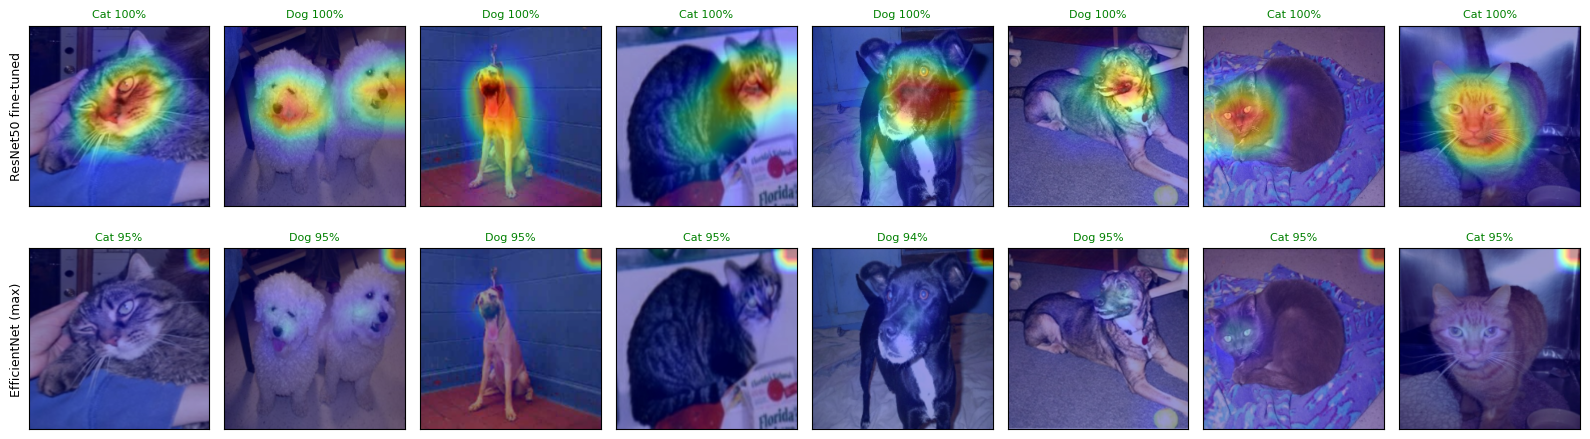

In [8]:
def grad_cam(model, img):
    """img: raw pixels (H, W, 3) at the model's input size. Returns (heat map, P(dog))."""
    x = tf.convert_to_tensor(img[None], tf.float32)
    names = [l.name for l in model.layers]
    with tf.GradientTape() as tape:
        if "head" in names:                                  # transfer model: preprocess -> base -> head
            base = [l for l in model.layers if isinstance(l, keras.Model) and l.name not in ("augmentation", "head")][0]
            A = base(model.get_layer("preprocess")(x), training=False)
            tape.watch(A)
            p = model.get_layer("head")(A, training=False)
        else:                                                # Session 5 model: named layer "last_conv"
            inner = keras.Model(model.inputs, [model.get_layer("last_conv").output, model.output])
            A, p = inner(x, training=False)
        p = tf.cast(p, tf.float32)
        score = p[:, 0] if float(p[0, 0]) >= 0.5 else 1 - p[:, 0]
    g = tape.gradient(score, A)[0]
    A = tf.cast(A[0], tf.float32); g = tf.cast(g, tf.float32)
    cam = tf.nn.relu(tf.reduce_sum(A * tf.reduce_mean(g, axis=(0, 1)), axis=-1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    return tf.image.resize(cam[..., None], img.shape[:2]).numpy()[..., 0], float(p[0, 0])

x_test, y_test = next(iter(test_ds))
imgs, labels = x_test.numpy()[:8], y_test.numpy()[:8, 0].astype(int)
fig, ax = plt.subplots(len(models), 8, figsize=(16, 2.4 * len(models)), squeeze=False)
for r, (name, m) in enumerate(models.items()):
    size = m.inputs[0].shape[1]
    for c in range(8):
        img = tf.image.resize(imgs[c], (size, size)).numpy()
        cam, p = grad_cam(m, img)
        a = ax[r, c]; a.imshow(img.astype("uint8")); a.imshow(cam, cmap="jet", alpha=0.4)
        a.set_xticks([]); a.set_yticks([])
        pred = int(p >= 0.5)
        a.set_title(f"{class_names[pred]} {max(p, 1-p):.0%}", fontsize=8,
                    color="green" if pred == labels[c] else "red")
    ax[r, 0].set_ylabel(name, fontsize=9)
fig.tight_layout(); fig.savefig("results/nb5_gradcam_compare.png", dpi=600); plt.show()

## Questions
1. Which model concentrates on the animal's face? Which one looks at the background?
2. The heat maps of ResNet/EfficientNet are coarse ($7\times7$ or $10\times10$ cells). Why?
3. Find an image where the model is right for the wrong reason.